# Notebook 3: Policy evaluation of NCAP

HST-105 Analytics for Business and Society

Team: Aashit Kumar Singh, Bhaskar Bhushan, Dhruv Singh Bisht

In this notebook we ask if NCAP (started in January 2019) lowered PM2.5 once we remove the effect of the weather (RQ2). We build a "no-policy" model from 2017-2018 weather and compare it with what really happened. Then we compare high-funded and low-funded cities with difference-in-differences and finish with a city scorecard.

## Setup
Here we import the libraries, set the folders, colours and plot style, and write the helper functions again so this notebook works on its own.

In [1]:
# Import the libraries we need and set paths, colours and plot style
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor

try:
    import geopandas as gpd
except ImportError:
    gpd = None
    print('geopandas is not installed: the map will be drawn without state borders.')

np.random.seed(42)

# Folders (the notebook runs from inside notebooks/)
datadir = '../data/'
procdir = '../data/processed/'
figdir = '../figures_outputs/'
os.makedirs(procdir, exist_ok=True)
os.makedirs(figdir, exist_ok=True)
panelpath = procdir + 'panel.csv'
smallpath = procdir + 'states-small.geojson'
ncappath = datadir + 'ncap_funding_data.pkl'
poppath = datadir + 'city_population.csv'

# Settings we may want to change
nearkm = 200            # a low-funded city is 'near' if a high-funded city is within this distance
unmatchedzero = False   # True = treat cities missing from the NCAP list as zero funding
igp = ['punjab', 'haryana', 'delhi', 'uttar pradesh', 'bihar', 'west bengal']

# Our muted palette (same as the paper)
teal = '#005468'
orange = '#BA6A3E'
slate = '#344054'
green = '#427A5A'
plum = '#74547C'
grey = '#9AA3AF'

# Plot style: white background, light grid, readable font, no top/right spines
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.grid': True,
    'grid.color': '#E5E7EB',
    'grid.linewidth': 0.6,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

In [2]:
# Helper functions: safe saving, name cleaning, finding columns, distance
def checkpath(path):
    # Only allow saving inside data/processed/ or figures_outputs/
    full = os.path.abspath(path)
    allowed = False
    for folder in [procdir, figdir]:
        if full.startswith(os.path.abspath(folder) + os.sep):
            allowed = True
    if not allowed:
        raise ValueError('Refusing to save outside data/processed/ or figures_outputs/: ' + path)


def savecsv(table, path):
    # Write to a temporary file first, then replace the real file in one step
    checkpath(path)
    tmp = path + '.tmp'
    table.to_csv(tmp, index=False)
    os.replace(tmp, path)
    print('Saved', path)


aliases = {'allahabad': 'prayagraj', 'gurgaon': 'gurugram', 'calcutta': 'kolkata'}


def cleanname(name):
    # Lowercase, strip spaces and replace old city names by new ones
    name = str(name).lower().strip()
    name = ' '.join(name.split())
    if name in aliases:
        name = aliases[name]
    return name


def statekey(name):
    # Make state names comparable: lowercase, '&' -> 'and', 'NCT of Delhi' -> 'delhi'
    name = str(name).lower().strip()
    name = name.replace('&', 'and')
    name = ' '.join(name.split())
    if 'delhi' in name:
        name = 'delhi'
    return name


def findcol(table, options):
    # Return the first column whose name matches one of the options (ignoring case)
    for option in options:
        for col in table.columns:
            if str(col).lower().strip() == option.lower():
                return col
    return None


def haversine(lat1, lon1, lat2, lon2):
    # Great-circle distance in km between two points given in degrees
    r = 6371.0
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    inside = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(inside))

In [3]:
# Choose the model: xgboost random forest on the GPU if possible, else CPU, else scikit-learn
modelkind = 'sklearn'
device = 'cpu'
try:
    import xgboost
    modelkind = 'xgboost'
except ImportError:
    print('xgboost is not installed, so we use the scikit-learn random forest.')

if modelkind == 'xgboost':
    try:
        tinyx = np.random.rand(50, 3)
        tinyy = np.random.rand(50)
        with warnings.catch_warnings():
            warnings.simplefilter('error')   # treat a GPU warning as a failure
            tiny = xgboost.XGBRFRegressor(n_estimators=5, max_depth=3, device='cuda', random_state=42)
            tiny.fit(tinyx, tinyy)
        device = 'cuda'
    except Exception as error:
        print('GPU (CUDA) not available, using the CPU. Reason:', str(error)[:150])
        device = 'cpu'

# Predicting from a table on the GPU gives a harmless speed warning; we hide it
warnings.filterwarnings('ignore', message='.*mismatched devices.*')


def makemodel():
    # Return a fresh, untrained random forest
    if modelkind == 'xgboost':
        return xgboost.XGBRFRegressor(n_estimators=300, max_depth=10, subsample=0.8,
                                      colsample_bynode=0.8, random_state=42, device=device)
    return RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                 n_jobs=-1, random_state=42)


if modelkind == 'xgboost':
    print('Model: xgboost XGBRFRegressor on', device)
else:
    print('Model: scikit-learn RandomForestRegressor on the CPU')

Model: xgboost XGBRFRegressor on cuda


## Step 1: Checking the input files
We need the station-day table and the small map file from Notebook 1, and the NCAP funding file in data/. If a file in data/processed/ ever looks broken, we can just delete it and run Notebook 1 again; it will be rebuilt from the original data.

In [4]:
# Check that the input files exist and print their size
def checkfiles(files):
    missing = []
    for path, advice in files:
        if os.path.exists(path):
            size = os.path.getsize(path) / 1e6
            print('OK       ', path, '(', round(size, 2), 'MB )')
        else:
            print('MISSING  ', path, '->', advice)
            missing.append(path)
    if len(missing) > 0:
        raise FileNotFoundError('Missing input files: ' + ', '.join(missing))


checkfiles([
    (panelpath, 'run Notebook 1 (01_data_and_geo_analysis) first'),
    (ncappath, 'download ncap_funding_data.pkl (VayuBench) into the data/ folder'),
])
if os.path.exists(smallpath):
    print('OK       ', smallpath)
else:
    print('WARNING: ', smallpath, 'is missing (run Notebook 1 to create it). The map will have no state borders.')

OK        ../data/processed/panel.csv ( 6.29 MB )
OK        ../data/ncap_funding_data.pkl ( 0.01 MB )
OK        ../data/processed/states-small.geojson


In [5]:
# Load the station-day table and the small map file
panel = pd.read_csv(panelpath, parse_dates=['date'])
print('Station-day table:', panel.shape)
print('Columns:', list(panel.columns))

states = None
try:
    if gpd is None:
        raise ImportError('geopandas is not installed')
    states = gpd.read_file(smallpath)
    states['key'] = states['statename'].apply(statekey)
    states['inigp'] = states['key'].isin(igp)
    print('Loaded the small map file')
except Exception as error:
    print('WARNING: could not load the map file (', error, '). The map will have no state borders.')
    states = None
panel.head(3)

Station-day table: (43830, 14)
Columns: ['date', 'station', 'city', 'state', 'lat', 'lon', 'pm', 'temp', 'humidity', 'wind', 'winddir', 'rain', 'nbravg', 'cluster']
Loaded the small map file


,date,station,city,state,lat,lon,pm,temp,humidity,wind,winddir,rain,nbravg,cluster
0,2017-01-01,"Ardhali Bazar, Varanasi - UPPCB",Varanasi,Uttar Pradesh,25.350599,82.908307,166.322111,16.95,83.0,12.0,82.0,0.0,NaN,2
1,2017-01-02,"Ardhali Bazar, Varanasi - UPPCB",Varanasi,Uttar Pradesh,25.350599,82.908307,178.818696,18.00,87.0,14.0,59.0,8.2,NaN,2
2,2017-01-03,"Ardhali Bazar, Varanasi - UPPCB",Varanasi,Uttar Pradesh,25.350599,82.908307,246.734270,17.70,83.0,11.6,284.0,0.0,NaN,2


## Step 2: The no-policy model
PM2.5 changes a lot with the weather, so we cannot just compare before and after 2019. Here we train a random forest on 2017-2018 only, using weather, calendar and place but no past PM2.5, so it tells us how polluted a day "should" be without NCAP. The gap is actual PM2.5 minus this prediction, and a negative gap means the air was cleaner than the weather alone would suggest. For 2017-2018 we predict each month with a model that did not see that month, so the early gap is not zero just because the model remembers it.

In [6]:
# Build the weather, calendar and place inputs (no past pm)
panel['month'] = panel['date'].dt.month
panel['dayofweek'] = panel['date'].dt.dayofweek
panel['dayofyear'] = panel['date'].dt.dayofyear
panel['year'] = panel['date'].dt.year

inputs = ['temp', 'humidity', 'wind', 'winddir', 'rain', 'month', 'dayofweek', 'dayofyear', 'lat', 'lon']
if 'humidity' not in panel.columns or panel['humidity'].isna().all():
    inputs.remove('humidity')
    print('No humidity in the data, so the baseline is built without it.')

base = panel.dropna(subset=['pm'] + inputs).copy()
pre = base[base['year'] <= 2018].copy()
later = base[base['year'] >= 2019].copy()
print('Inputs:', inputs)
print('Rows 2017-2018 (training):', len(pre), '  Rows 2019-2024:', len(later))

Inputs: ['temp', 'humidity', 'wind', 'winddir', 'rain', 'month', 'dayofweek', 'dayofyear', 'lat', 'lon']
Rows 2017-2018 (training): 8910   Rows 2019-2024: 31197


In [7]:
# Out-of-sample predictions for 2017-2018: each calendar month is predicted by a model that never saw it
folds = GroupKFold(n_splits=5)
prepred = np.full(len(pre), np.nan)
fold = 0
for trainidx, testidx in folds.split(pre[inputs], pre['pm'], groups=pre['month']):
    fold = fold + 1
    model = makemodel()
    model.fit(pre[inputs].iloc[trainidx], pre['pm'].iloc[trainidx])
    prepred[testidx] = model.predict(pre[inputs].iloc[testidx])
    print('Fold', fold, 'done: held-out months', sorted(pre['month'].iloc[testidx].unique()))
pre['nopolicy'] = prepred

# Model trained on all of 2017-2018 predicts 2019-2024
final = makemodel()
final.fit(pre[inputs], pre['pm'])
later['nopolicy'] = final.predict(later[inputs])

base = pd.concat([pre, later]).sort_values(['station', 'date']).reset_index(drop=True)
base['gap'] = base['pm'] - base['nopolicy']
base['ym'] = base['date'].dt.to_period('M').dt.to_timestamp()
print('Average gap 2017-2018:', round(base[base['year'] <= 2018]['gap'].mean(), 2), 'µg/m³')
print('Average gap 2019-2024:', round(base[base['year'] >= 2019]['gap'].mean(), 2), 'µg/m³')

Fold 1 done: held-out months [np.int32(4), np.int32(11)]
Fold 2 done: held-out months [np.int32(8), np.int32(9), np.int32(12)]
Fold 3 done: held-out months [np.int32(5), np.int32(7)]
Fold 4 done: held-out months [np.int32(1), np.int32(6)]
Fold 5 done: held-out months [np.int32(2), np.int32(3), np.int32(10)]
Average gap 2017-2018: -1.99 µg/m³
Average gap 2019-2024: -34.74 µg/m³


### Delhi: actual vs no-policy PM2.5
Here we plot the monthly average of the Delhi stations, with the training years shaded grey and the start of NCAP as a dashed line.

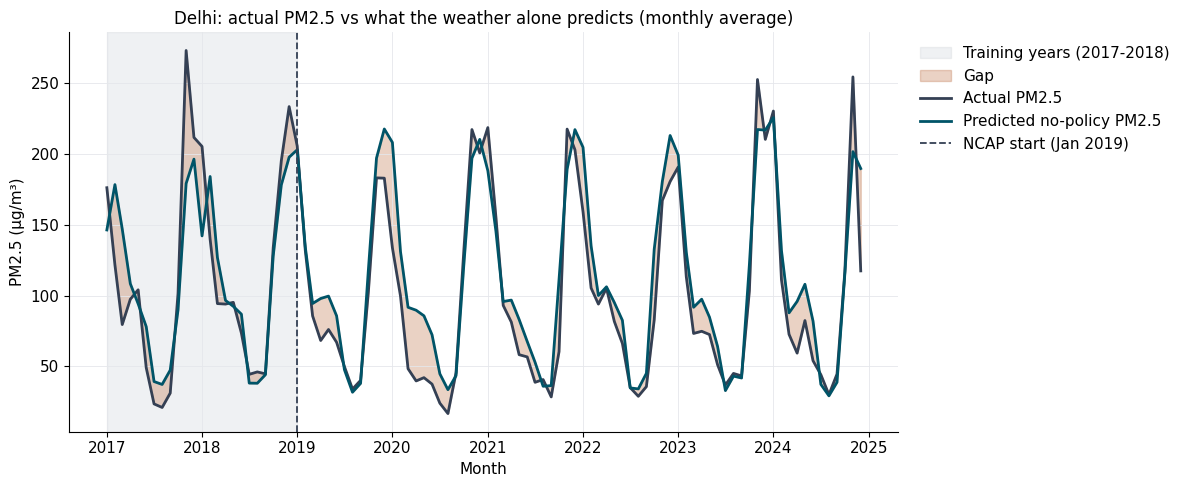

In [8]:
# Monthly actual and no-policy PM2.5 for Delhi
delhi = base[base['city'] == 'Delhi'].groupby('ym')[['pm', 'nopolicy']].mean()
if len(delhi) == 0:
    print('No Delhi stations in the data, so this figure is skipped.')
else:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.axvspan(pd.Timestamp('2017-01-01'), pd.Timestamp('2019-01-01'), color=grey, alpha=0.15, label='Training years (2017-2018)')
    ax.fill_between(delhi.index, delhi['pm'], delhi['nopolicy'], color=orange, alpha=0.3, label='Gap')
    ax.plot(delhi.index, delhi['pm'], color=slate, linewidth=2, label='Actual PM2.5')
    ax.plot(delhi.index, delhi['nopolicy'], color=teal, linewidth=2, label='Predicted no-policy PM2.5')
    ax.axvline(pd.Timestamp('2019-01-01'), color=slate, linestyle='--', linewidth=1.3, label='NCAP start (Jan 2019)')
    ax.set_xlabel('Month')
    ax.set_ylabel('PM2.5 (µg/m³)')
    ax.set_title('Delhi: actual PM2.5 vs what the weather alone predicts (monthly average)')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.savefig(figdir + 'nb3-no-policy-baseline.png', dpi=300, bbox_inches='tight')
    plt.show()

**Observation:** In 2017-2018 the predicted line follows the actual line well. From 2019, actual PM2.5 is often below what the weather alone predicts, with the clearest gap in spring and summer 2020.

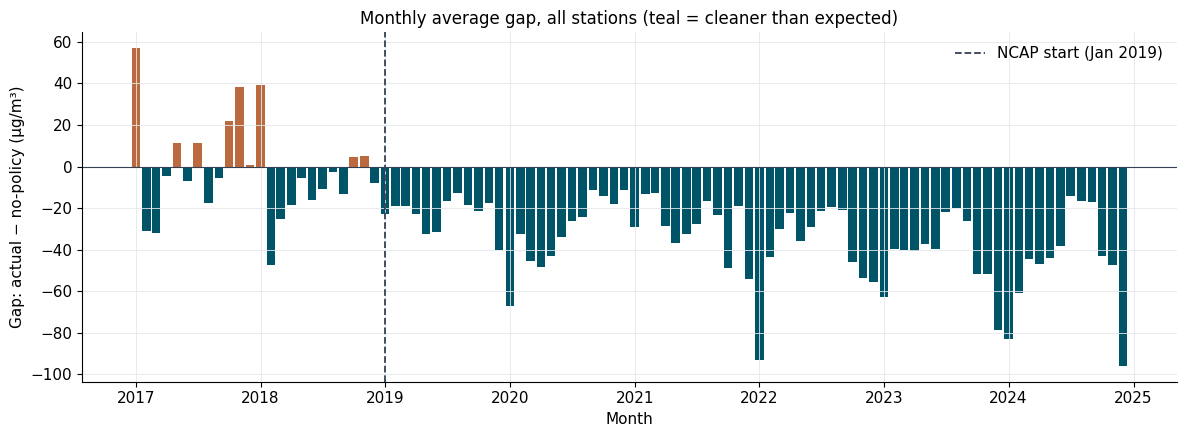

In [9]:
# Monthly average gap over all stations
monthgap = base.groupby('ym')['gap'].mean()
barcolours = []
for value in monthgap.values:
    if value < 0:
        barcolours.append(teal)
    else:
        barcolours.append(orange)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(monthgap.index, monthgap.values, width=25, color=barcolours)
ax.axhline(0, color=slate, linewidth=0.8)
ax.axvline(pd.Timestamp('2019-01-01'), color=slate, linestyle='--', linewidth=1.3, label='NCAP start (Jan 2019)')
ax.set_xlabel('Month')
ax.set_ylabel('Gap: actual − no-policy (µg/m³)')
ax.set_title('Monthly average gap, all stations (teal = cleaner than expected)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(figdir + 'nb3-monthly-gap.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The gap is mixed in 2017 but already turns negative during 2018, before NCAP, and stays negative after 2019. So part of the fall is a general downward trend that started before NCAP.

## Step 3: COVID check
In April-May 2020 India was in a strict lockdown. If our method works, the gap in April-May 2020 should be lower than in the other years.

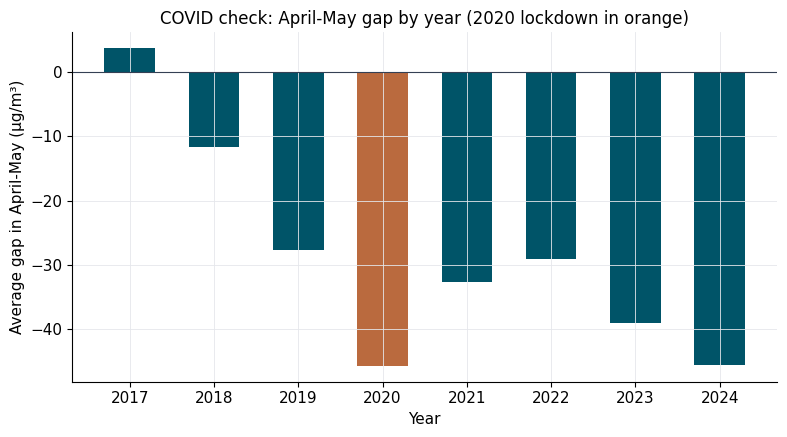

year
2017     3.72
2018   -11.60
2019   -27.71
2020   -45.74
2021   -32.61
2022   -29.05
2023   -39.13
2024   -45.63
Name: gap, dtype: float64

In [10]:
# Average gap in April-May of each year, with 2020 highlighted
aprmay = base[base['month'].isin([4, 5])].groupby('year')['gap'].mean()
barcolours = []
for year in aprmay.index:
    if year == 2020:
        barcolours.append(orange)
    else:
        barcolours.append(teal)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(aprmay.index.astype(str), aprmay.values, color=barcolours, width=0.6)
ax.axhline(0, color=slate, linewidth=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Average gap in April-May (µg/m³)')
ax.set_title('COVID check: April-May gap by year (2020 lockdown in orange)')
plt.tight_layout()
plt.savefig(figdir + 'nb3-covid-check.png', dpi=300, bbox_inches='tight')
plt.show()
aprmay.round(2)

**Observation:** The April-May gap is -28 in 2019, -46 in 2020 and -33 in 2021, so the 2020 lockdown shows a clear extra dip compared with the years around it and the method can pick up a real change. But 2024 is just as low (-46), so the dip does not stand out on its own.

## Step 4: Adding the NCAP funds
Now we take the average gap per city per month and attach the NCAP funds of each city, after cleaning the city names. A city is high-funded if its funds are above the median of the matched cities. Cities that are not in the NCAP list are left out of the comparison.

In [11]:
# City-month average gap, with year and the post-NCAP flag
citygap = base.groupby(['city', 'ym'])['gap'].mean().reset_index()
citygap['year'] = citygap['ym'].dt.year
citygap['post'] = (citygap['ym'] >= pd.Timestamp('2019-01-01')).astype(int)

# Load the NCAP funding file (read only) and look at it
ncap = pd.read_pickle(ncappath)
print('NCAP file:', ncap.shape)
print('Columns:', list(ncap.columns))
ncap.head(3)

NCAP file: (117, 8)
Columns: ['S. No.', 'state', 'city', 'Amount released during FY 2019-20', 'Amount released during FY 2020-21', 'Amount released during FY 2021-22', 'Total fund released', 'Utilisation as on June 2022']


,S. No.,state,city,Amount released during FY 2019-20,Amount released during FY 2020-21,Amount released during FY 2021-22,Total fund released,Utilisation as on June 2022
0,1,Andhra Pradesh,Vijaywada,6.00,NaN,NaN,6.00,22.91
1,2,Andhra Pradesh,Guntur,0.12,0.76,1.96,2.84,22.91
2,3,Andhra Pradesh,Kurnool,0.06,0.76,1.36,2.18,22.91


In [12]:
# Find the city and total-funds columns and match the cities
citycol = findcol(ncap, ['city', 'city name', 'name of city'])
fundcol = None
for col in ncap.columns:
    if 'total' in str(col).lower():
        fundcol = col
        break
if citycol is None or fundcol is None:
    raise KeyError('Could not find the city or total-funds column in the NCAP file. Columns: ' + str(list(ncap.columns)))
print('City column:', citycol, '   Funds column:', fundcol)

funds = ncap[[citycol, fundcol]].copy()
funds.columns = ['ncapcity', 'funds']
funds['key'] = funds['ncapcity'].apply(cleanname)
funds = funds.groupby('key', as_index=False)['funds'].sum()

cities = pd.DataFrame({'city': sorted(base['city'].unique())})
cities['key'] = cities['city'].apply(cleanname)
cities = cities.merge(funds, on='key', how='left')
unmatched = list(cities[cities['funds'].isna()]['city'])
print('Cities in our data without a match in the NCAP file:', unmatched)
if unmatchedzero:
    cities['funds'] = cities['funds'].fillna(0)
    print('unmatchedzero = True: these cities are treated as zero funding.')

# Funds per person if we have population, otherwise total funds
if os.path.exists(poppath):
    pop = pd.read_csv(poppath)
    pop['key'] = pop['city'].apply(cleanname)
    pop = pop.groupby('key', as_index=False)['population'].sum()
    cities = cities.merge(pop, on='key', how='left')
    cities['measure'] = cities['funds'] * 1e7 / cities['population']   # 1 crore = 10 million rupees
    print('Using funds per person (Rs per person).')
else:
    cities['measure'] = cities['funds']
    print('Note: data/city_population.csv not found, so we use total funds (Rs crore) instead of funds per person.')

matched = cities[cities['measure'].notna()]
if len(matched) < 2:
    raise ValueError('Fewer than 2 cities matched the NCAP file, so we cannot split high and low.')
median = matched['measure'].median()
cities['high'] = np.nan
cities.loc[cities['measure'] > median, 'high'] = 1
cities.loc[cities['measure'] <= median, 'high'] = 0
print('Median funding:', round(median, 3))
print('High-funded cities:', list(cities[cities['high'] == 1]['city']))
print('Low-funded cities: ', list(cities[cities['high'] == 0]['city']))
cities

City column: city    Funds column: Total fund released
Cities in our data without a match in the NCAP file: ['Faridabad', 'Gurugram']
Note: data/city_population.csv not found, so we use total funds (Rs crore) instead of funds per person.
Median funding: 9.45
High-funded cities: ['Delhi', 'Patna', 'Varanasi']
Low-funded cities:  ['Agra', 'Amritsar', 'Gaya', 'Kanpur', 'Lucknow', 'Ludhiana', 'Muzaffarpur']


,city,key,funds,measure,high
0,Agra,agra,9.45,9.45,0.0
1,Amritsar,amritsar,6.00,6.00,0.0
2,Delhi,delhi,11.25,11.25,1.0
3,Faridabad,faridabad,NaN,NaN,NaN
4,Gaya,gaya,4.00,4.00,0.0
5,Gurugram,gurugram,NaN,NaN,NaN
6,Kanpur,kanpur,9.45,9.45,0.0
7,Lucknow,lucknow,9.45,9.45,0.0
8,Ludhiana,ludhiana,6.00,6.00,0.0
9,Muzaffarpur,muzaffarpur,7.60,7.60,0.0


**Observation:** We used total NCAP funds because we have no population file. Delhi (11.25 crore), Patna (10.0) and Varanasi (9.47) are high-funded, while Agra, Kanpur, Lucknow (9.45 each), Muzaffarpur (7.6), Amritsar, Ludhiana (6.0) and Gaya (4.0) are low-funded, and Gurugram and Faridabad could not be matched. The median is exactly 9.45, so Agra, Kanpur and Lucknow fall just below the line, which makes the split fragile.

## Step 5: Difference-in-differences
Here we check if the gap fell more after 2019 in high-funded cities than in low-funded cities. The "high x post" term is the extra change in high-funded cities, and we cluster the standard errors by city. We run it with all years and again without 2020, so the lockdown does not drive the result.

In [13]:
# Difference-in-differences with standard errors clustered by city
did = citygap.merge(cities[['city', 'high']], on='city', how='inner')
did = did.dropna(subset=['high', 'gap']).copy()
did['high'] = did['high'].astype(int)


def runols(formula, table, label):
    # Fit the regression and return a clean table of coefficients
    groups = pd.factorize(table['city'])[0]
    fit = smf.ols(formula, data=table).fit(cov_type='cluster', cov_kwds={'groups': groups})
    out = pd.DataFrame({
        'run': label,
        'term': fit.params.index,
        'coef': fit.params.values,
        'se': fit.bse.values,
        'pvalue': fit.pvalues.values,
    })
    out['cities'] = table['city'].nunique()
    out['rows'] = len(table)
    return out


nhigh = did[did['high'] == 1]['city'].nunique()
nlow = did[did['high'] == 0]['city'].nunique()
print('High-funded cities:', nhigh, '  Low-funded cities:', nlow)
results = []
if nhigh < 2 or nlow < 2:
    print('Too few cities in one group for a difference-in-differences test.')
else:
    try:
        results.append(runols('gap ~ high + post + high:post', did, 'All years'))
        results.append(runols('gap ~ high + post + high:post', did[did['year'] != 2020], 'Without 2020'))
    except Exception as error:
        print('The regression failed:', error)

if len(results) > 0:
    didresults = pd.concat(results, ignore_index=True)
    savecsv(didresults.round(4), figdir + 'nb3-did-results.csv')
    print(didresults.round(3).to_string(index=False))

High-funded cities: 3   Low-funded cities: 7
Saved ../figures_outputs/nb3-did-results.csv
         run      term    coef     se  pvalue  cities  rows
   All years Intercept  -3.192  3.035   0.293      10   943
   All years      high   4.880  3.716   0.189      10   943
   All years      post -30.255  7.806   0.000      10   943
   All years high:post  -9.115 15.945   0.568      10   943
Without 2020 Intercept  -3.192  3.035   0.293      10   827
Without 2020      high   4.880  3.717   0.189      10   827
Without 2020      post -31.478  8.612   0.000      10   827
Without 2020 high:post  -8.788 17.517   0.616      10   827


**Observation:** With all years, post = -30.3 (p < 0.001) and high x post = -9.1 (SE 15.9, p = 0.57); without 2020 they are -31.5 and -8.8 (p = 0.62). All cities are about 30 µg/m³ cleaner than their weather predicts after 2019, but because the decline began in 2018 we cannot credit all of it to NCAP. High-funded cities improved about 9 µg/m³ more, which is the expected direction, but with only 10 cities this is not statistically significant.

### High-funded vs low-funded cities year by year
This method needs the two groups to move in parallel before 2019, so we plot the yearly average gap of both groups.

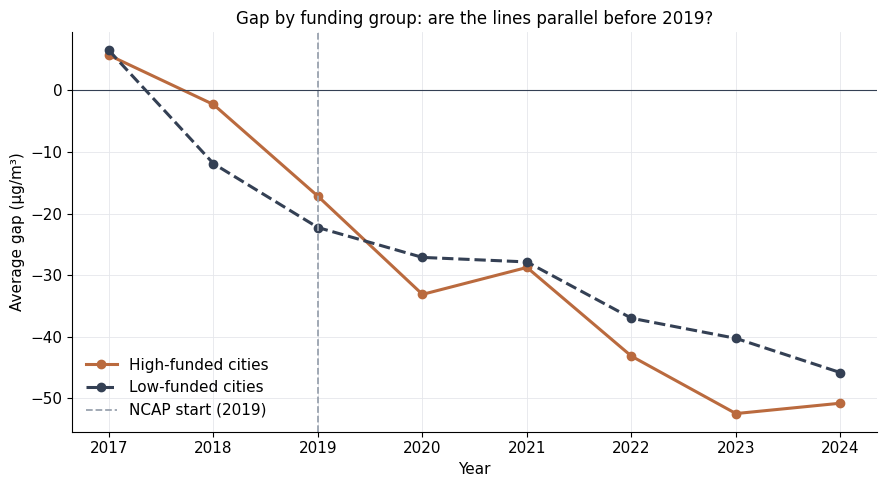

high,0,1
year,,
2017,6.45,5.69
2018,-11.91,-2.31
2019,-22.27,-17.20
2020,-27.12,-33.12
2021,-27.86,-28.75
2022,-36.99,-43.15
2023,-40.26,-52.46
2024,-45.82,-50.78


In [14]:
# Yearly average gap for high-funded and low-funded cities
yearly = did.groupby(['year', 'high'])['gap'].mean().unstack('high')
fig, ax = plt.subplots(figsize=(9, 5))
if 1 in yearly.columns:
    ax.plot(yearly.index, yearly[1], color=orange, linewidth=2.2, marker='o', label='High-funded cities')
if 0 in yearly.columns:
    ax.plot(yearly.index, yearly[0], color=slate, linewidth=2.2, marker='o', linestyle='--', label='Low-funded cities')
ax.axvline(2019, color=grey, linestyle='--', linewidth=1.3, label='NCAP start (2019)')
ax.axhline(0, color=slate, linewidth=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Average gap (µg/m³)')
ax.set_title('Gap by funding group: are the lines parallel before 2019?')
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(figdir + 'nb3-did-lines.png', dpi=300, bbox_inches='tight')
plt.show()
yearly.round(2)

**Observation:** The two groups start together in 2017, but in 2018 the low-funded cities fall faster, so the lines are not fully parallel before NCAP. After 2021 the high-funded cities fall further below their no-policy level.

## Step 6: Spillover check
Air does not stop at city borders, so a low-funded city may also gain if a high-funded city is close by. Among the low-funded cities, we mark a city as "near" if a high-funded city is within 200 km (haversine distance) and run the same kind of regression with near instead of high.

In [15]:
# Mark low-funded cities that have a high-funded city within nearkm
centres = base.groupby('city')[['lat', 'lon']].mean()
highcities = list(cities[cities['high'] == 1]['city'])
lowcities = list(cities[cities['high'] == 0]['city'])
nearrows = []
for city in lowcities:
    close = 0
    for other in highcities:
        d = haversine(centres.loc[city, 'lat'], centres.loc[city, 'lon'],
                      centres.loc[other, 'lat'], centres.loc[other, 'lon'])
        if d <= nearkm:
            close = 1
    nearrows.append({'city': city, 'near': close})
nearness = pd.DataFrame(nearrows, columns=['city', 'near'])
print(nearness.to_string(index=False))

# Spillover regression on low-funded cities only
low = did[did['high'] == 0].merge(nearness, on='city', how='inner')
nnear = (nearness['near'] == 1).sum()
nfar = (nearness['near'] == 0).sum()
if nnear < 2 or nfar < 2:
    print('Too few low-funded cities near / far from high-funded cities (', nnear, 'near,', nfar,
          'far ) for the spillover model, so it is skipped.')
else:
    try:
        spill = runols('gap ~ near + post + near:post', low, 'Low-funded cities')
        savecsv(spill.round(4), figdir + 'nb3-spillover-results.csv')
        print(spill.round(3).to_string(index=False))
    except Exception as error:
        print('The spillover regression failed:', error)

       city  near
       Agra     1
   Amritsar     0
       Gaya     1
     Kanpur     0
    Lucknow     0
   Ludhiana     0
Muzaffarpur     1
Saved ../figures_outputs/nb3-spillover-results.csv
              run      term    coef     se  pvalue  cities  rows
Low-funded cities Intercept  -0.531  4.891   0.914       7   658
Low-funded cities      near  -6.006  5.147   0.243       7   658
Low-funded cities      post -25.031 12.665   0.048       7   658
Low-funded cities near:post -12.590 13.691   0.358       7   658


**Observation:** With 7 low-funded cities, near x post = -12.6 (p = 0.36). Low-funded cities close to a high-funded city improved more, which fits the shared-air idea, but it is not significant.

## Step 7: City scorecard
Here we make one row per city with its mean gap after 2019 (without 2020), its funds, its group, near and its airshed from Notebook 1. Then we draw it on a map, where blue means cleaner than the weather predicts and bigger circles mean more NCAP money.

In [16]:
# One row per city: mean gap after 2019 (without 2020), funds, group, near, airshed
after = citygap[(citygap['year'] >= 2019) & (citygap['year'] != 2020)]
card = after.groupby('city')['gap'].mean().rename('meangap').reset_index()
card = card.merge(cities[['city', 'funds', 'measure', 'high']], on='city', how='left')
card = card.merge(nearness, on='city', how='left')
card = card.merge(centres.reset_index(), on='city', how='left')


def mostcommon(values):
    values = values.dropna()
    if len(values) == 0:
        return np.nan
    return values.value_counts().index[0]


if 'cluster' in panel.columns:
    stationinfo = panel.groupby('station')[['city', 'cluster']].first()
    citycluster = stationinfo.groupby('city')['cluster'].apply(mostcommon)
    card['cluster'] = card['city'].map(citycluster)
else:
    print('No cluster column in panel.csv (run Notebook 1 to the end).')
    card['cluster'] = np.nan

card = card.sort_values('meangap').reset_index(drop=True)
savecsv(card.round(3), figdir + 'nb3-city-scorecard.csv')
card.round(2)

Saved ../figures_outputs/nb3-city-scorecard.csv


,city,meangap,funds,measure,high,near,lat,lon,cluster
0,Varanasi,-72.17,9.47,9.47,1.0,NaN,25.35,82.91,2
1,Agra,-62.75,9.45,9.45,0.0,1.0,27.20,78.01,2
2,Gurugram,-53.95,NaN,NaN,NaN,NaN,28.44,77.08,1
3,Kanpur,-48.75,9.45,9.45,0.0,0.0,26.47,80.32,2
4,Lucknow,-41.16,9.45,9.45,0.0,0.0,26.84,80.91,2
5,Gaya,-36.71,4.00,4.00,0.0,1.0,24.80,85.00,2
6,Muzaffarpur,-36.55,7.60,7.60,0.0,1.0,26.12,85.36,2
7,Patna,-32.90,10.00,10.00,1.0,NaN,25.61,85.13,2
8,Faridabad,-24.16,NaN,NaN,NaN,NaN,28.41,77.31,1
9,Amritsar,-11.28,6.00,6.00,0.0,0.0,31.62,74.88,3


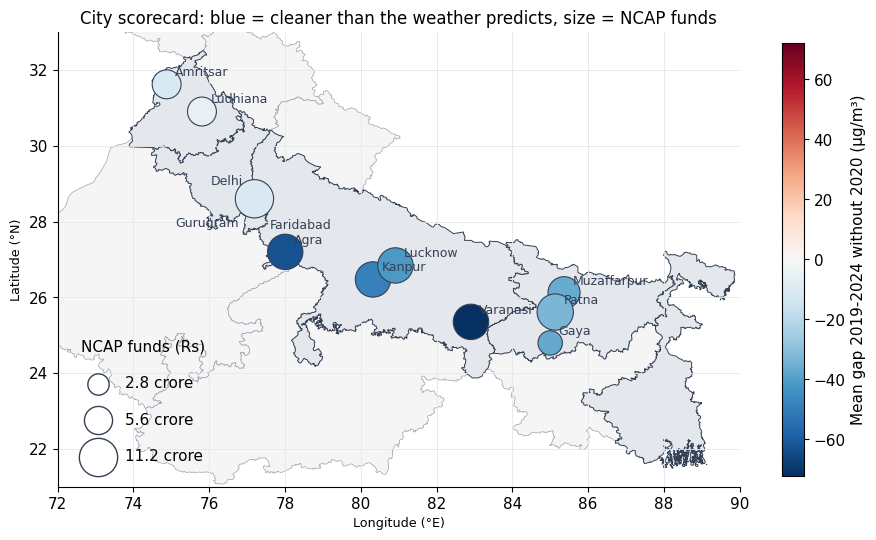

In [18]:
# Scorecard map: colour = mean gap (centred at 0), size = NCAP funds
def drawmap(ax):
    # State borders (if we have them) and the map window
    if states is not None:
        states[~states['inigp']].plot(ax=ax, color='#F5F5F5', edgecolor=grey, linewidth=0.5)
        states[states['inigp']].plot(ax=ax, color='#E4E7EC', edgecolor=slate, linewidth=0.7)
    ax.set_xlim(72, 90)
    ax.set_ylim(21, 33)
    ax.set_aspect('equal')
    ax.set_xlabel('Longitude (°E)')
    ax.set_ylabel('Latitude (°N)')


limit = np.nanmax(np.abs(card['meangap']))
norm = Normalize(vmin=-limit, vmax=limit)
fundmax = card['funds'].max()
if np.isnan(fundmax) or fundmax <= 0:
    fundmax = 1
sizes = 60 + 700 * card['funds'].fillna(0) / fundmax

fig, ax = plt.subplots(figsize=(11, 7.5))
drawmap(ax)
points = ax.scatter(card['lon'], card['lat'], c=card['meangap'], cmap='RdBu_r', norm=norm,
                    s=sizes, edgecolor=slate, linewidth=0.8, zorder=3)
# Small manual offsets (x, y in points, text alignment) so the labels around Delhi do not overlap
offsets = {'Delhi': (-8, 10, 'right'), 'Gurugram': (-8, -16, 'right'), 'Faridabad': (8, -16, 'left')}
for i in range(len(card)):
    city = card.loc[i, 'city']
    dx, dy, align = offsets.get(city, (6, 6, 'left'))
    ax.annotate(city, (card.loc[i, 'lon'], card.loc[i, 'lat']), xytext=(dx, dy), ha=align,
                textcoords='offset points', fontsize=9, color=slate)

# Size legend: three example fund amounts
for value in [fundmax / 4, fundmax / 2, fundmax]:
    ax.scatter([], [], s=60 + 700 * value / fundmax, color='white', edgecolor=slate,
               label=f'{value:.1f} crore')
ax.legend(title='NCAP funds (Rs)', loc='lower left', labelspacing=1.4, borderpad=1)
fig.colorbar(points, ax=ax, shrink=0.75, label='Mean gap 2019-2024 without 2020 (µg/m³)')
ax.set_title('City scorecard: blue = cleaner than the weather predicts, size = NCAP funds')
plt.savefig(figdir + 'nb3-scorecard-map.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The mean gaps are Varanasi -72, Agra -63, Gurugram -54, Kanpur -49, Lucknow -41, Gaya -37, Muzaffarpur -37, Patna -33, Faridabad -24, Amritsar -11, Delhi -10 and Ludhiana -6. The Uttar Pradesh cities improved the most compared with their weather. Delhi received the most money but improved the least, together with the Punjab cities.

## Other policies
We do not test the 2015 crop-burning ban or Delhi's odd-even rule, because our station data starts in 2017. Later we could add NASA FIRMS satellite fire data, so that a year with fewer farm fires is not mistaken for a policy success.

## Summary
In this notebook we built a weather-only no-policy model and found that, after removing the effect of the weather, PM2.5 fell in all our cities after 2019, by about 30 µg/m³. But part of this fall began in 2018, before NCAP, so we cannot credit all of it to NCAP. High-funded cities improved about 9 µg/m³ more and low-funded cities near them also improved more, but neither effect is significant with only 10 cities. So our answer to RQ2 is "probably some effect, but not proven", and a larger sample of cities with funds per person would be needed for a firm answer. The scorecard, airsheds and forecast still point to our policy ideas: judge cities by their weather-adjusted gap, plan by airshed, build early warning and make funding fairer.